<a href="https://colab.research.google.com/github/veorte/registros/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Verónica Ortega López
*   MATRÍCULA: A01841596

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [34]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer
from scipy import stats

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [35]:
cardio_df = pd.read_csv('heart_disease.csv')

cardio_df.set_index('id', inplace=True)

cardio_df.head()

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [36]:
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


In [37]:
cardio_df.select_dtypes(include='number').shape[1]

7

In [38]:
cardio_df.select_dtypes(include='object').shape[1]

8

Contamos con 8 columnas númericas y 7 columnas de tipo objeto (texto y valores categóricos)

In [39]:
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


En la tabla anterior se observan los valores unicos por columna.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [40]:
cardio_df['num'] = pd.Categorical(
    cardio_df['num'],
    categories=[0, 1, 2, 3, 4],
    ordered=True
)

cardio_df['num'].dtype

CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True, categories_dtype=int64)

In [41]:
categoricas_nominales = [
    'sex', 'origin', 'cp', 'fbs',
    'restecg', 'exang', 'thal'
]

for columna in categoricas_nominales:
    cardio_df[columna] = cardio_df[columna].astype('category')

cardio_df['slope'] = pd.Categorical(
    cardio_df['slope'],
    categories=['downsloping', 'flat', 'upsloping'],
    ordered=True
)

cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       918 non-null    int64   
 1   sex       918 non-null    category
 2   origin    918 non-null    category
 3   cp        918 non-null    category
 4   trestbps  859 non-null    float64 
 5   chol      888 non-null    float64 
 6   fbs       829 non-null    category
 7   restecg   918 non-null    category
 8   thalch    863 non-null    float64 
 9   exang     863 non-null    category
 10  oldpeak   856 non-null    float64 
 11  slope     610 non-null    category
 12  ca        309 non-null    float64 
 13  thal      434 non-null    category
 14  num       918 non-null    category
dtypes: category(9), float64(5), int64(1)
memory usage: 59.5 KB


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [42]:
numericas = cardio_df.select_dtypes(include='number')

estadisticas_num = numericas.describe().T

estadisticas_num['sesgo'] = numericas.skew()
estadisticas_num['curtosis'] = numericas.kurt()

display(estadisticas_num.round(2))

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.53,9.41,28.0,47.0,54.0,60.0,77.0,-0.19,-0.38
trestbps,859.0,132.29,18.54,80.0,120.0,130.0,140.0,200.0,0.63,0.63
chol,888.0,242.19,53.42,85.0,216.0,223.0,268.0,603.0,1.64,6.57
thalch,863.0,137.53,25.95,60.0,120.0,140.0,157.0,202.0,-0.21,-0.48
oldpeak,856.0,0.88,1.09,-2.6,0.0,0.5,1.5,6.2,1.04,1.12
ca,309.0,0.68,0.94,0.0,0.0,0.0,1.0,3.0,1.17,0.20


In [43]:
categoricas = cardio_df.select_dtypes(
    include=['object', 'category']
)

display(categoricas.describe().T)

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
thal,434,3,normal,196
num,918,5,0,411


In [44]:
for columna in categoricas.columns:
    print(f"\nVariable: {columna}")

    frecuencias = cardio_df[columna].value_counts(
        dropna=False
    )

    porcentajes = cardio_df[columna].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    tabla = pd.DataFrame({
        'Frecuencia': frecuencias,
        'Porcentaje': porcentajes.round(2)
    })

    display(tabla)


Variable: sex


,Frecuencia,Porcentaje
sex,,
Male,724,78.87
Female,194,21.13



Variable: origin


,Frecuencia,Porcentaje
origin,,
Cleveland,304,33.12
Hungary,292,31.81
VA Long Beach,200,21.79
Switzerland,122,13.29



Variable: cp


...

,Frecuencia,Porcentaje
slope,,
flat,345,37.58
NaN,308,33.55
upsloping,202,22.00
downsloping,63,6.86



Variable: thal


,Frecuencia,Porcentaje
thal,,
NaN,484,52.72
normal,196,21.35
reversable defect,192,20.92
fixed defect,46,5.01



Variable: num


,Frecuencia,Porcentaje
num,,
0,411,44.77
1,263,28.65
2,109,11.87
3,107,11.66
4,28,3.05


4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [45]:
porcentaje_faltantes = (
    cardio_df.isna().mean() * 100
).sort_values(ascending=False)

display(porcentaje_faltantes.round(2))

,0
ca,66.34
thal,52.72
slope,33.55
fbs,9.69
oldpeak,6.75
trestbps,6.43
thalch,5.99
exang,5.99
chol,3.27
sex,0.00


In [46]:
# Eliminar variables con faltantes mayores a 30%

columnas_eliminar = porcentaje_faltantes[
    porcentaje_faltantes > 30
].index

print("Columnas que se eliminarán:")
print(columnas_eliminar.tolist())

cardio_df.drop(
    columns=columnas_eliminar,
    inplace=True
)

print("Dimensiones restantes:", cardio_df.shape)

Columnas que se eliminarán:
['ca', 'thal', 'slope']
Dimensiones restantes: (918, 12)


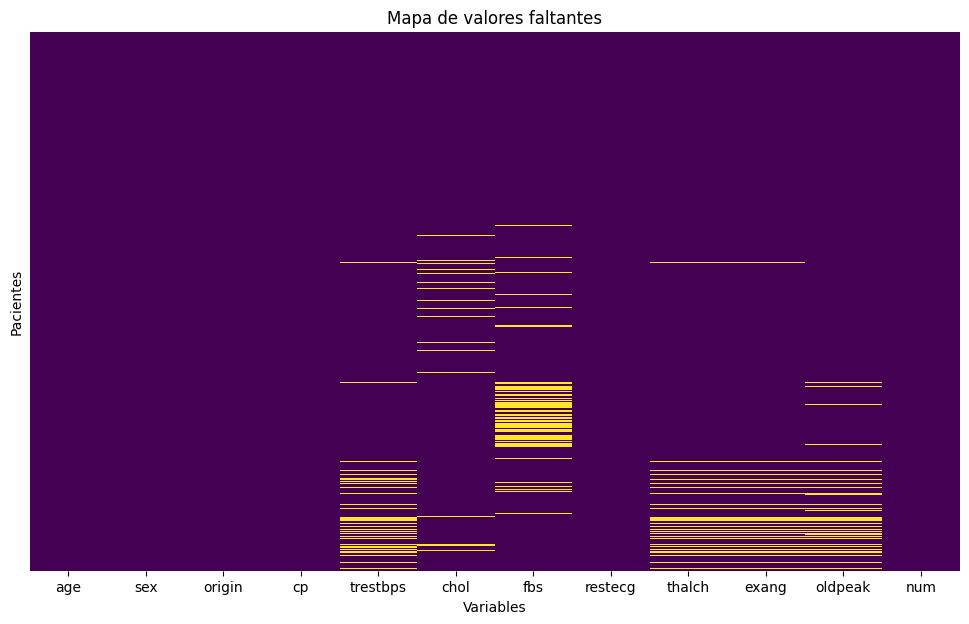

In [47]:
# Mapa de calor para visualizar la distribución de los valores faltantes

plt.figure(figsize=(12, 7))

sns.heatmap(
    cardio_df.isna(),
    cmap='viridis',
    cbar=False,
    yticklabels=False
)

plt.title('Mapa de valores faltantes')
plt.xlabel('Variables')
plt.ylabel('Pacientes')

plt.show()

In [48]:
# Para comprobar númericamente la coincidencia entre las varialbes trestbps, thalch, exang, oldpeak

variables_patron = [
    'thalch', 'exang', 'oldpeak', 'trestbps'
]

matriz_faltantes = (
    cardio_df[variables_patron].isna().astype(int)
)

display(matriz_faltantes.corr().round(2))

,thalch,exang,oldpeak,trestbps
thalch,1.00,1.00,0.92,0.96
exang,1.00,1.00,0.92,0.96
oldpeak,0.92,0.92,1.00,0.90
trestbps,0.96,0.96,0.90,1.00


De acuerdo al significado encontrando para cada una de las variables:

*   ***thalch*** - registra la frecuencia cardíaca máxima alcanzada
*   ***exang*** indica si hubo angina inducida por ejercicio
*   ***oldpeak*** mide cambios del segmento ST relacionados con el ejercicio
* ***trestbps*** - presión arterial en reposo

y de acuerdo a la literatura médica, las tres primeras variables pueden obtnerse durante una prueba de esfuerzo.  Si un paciente no se sometió a ella, las tres variables podrían faltar al mismo tiempo.

En el caso de ***trestbps***, aunque no depende necesariamente de una prueba de esfuerzo, si podría faltar junto con las demás por un registro clínico incompleto o por diferencias en los procedimientos.

En conclusión la concurrencia si tiene una explicación clínica y operativa posible, sin embargo, el conjunto de los datos no permite demostrar la causa exacta de las ausencias de datos.







5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [49]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [50]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

In [51]:
# Crear dos grupos de pacientes

cardio_df['thalch_faltante'] = cardio_df['thalch'].isna()

cardio_df['thalch_faltante'].value_counts()

,count
thalch_faltante,
False,863
True,55


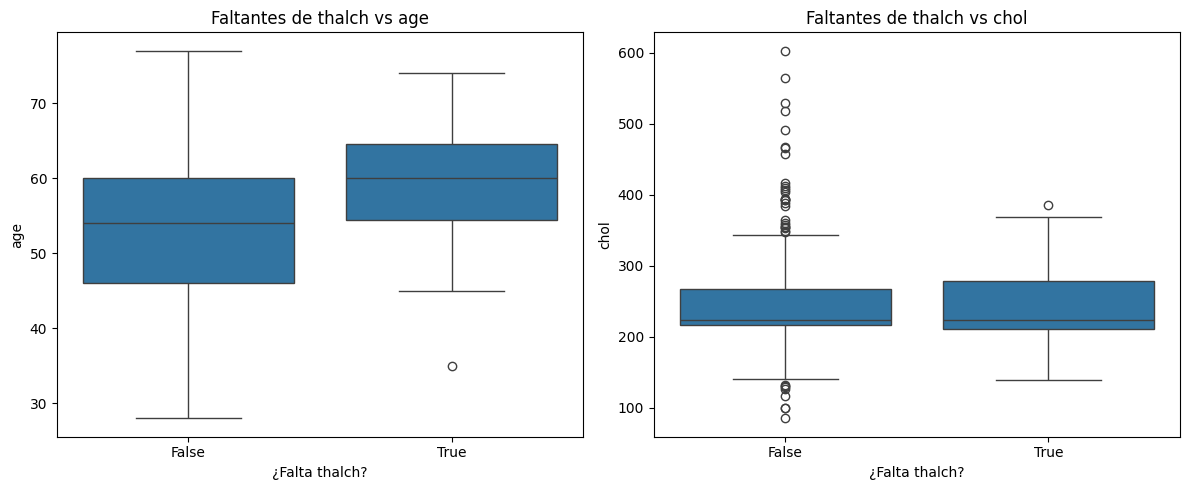

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, variable in enumerate(['age', 'chol']):
    sns.boxplot(
        data=cardio_df,
        x='thalch_faltante',
        y=variable,
        ax=axes[i]
    )

    axes[i].set_title(f'Faltantes de thalch vs {variable}')
    axes[i].set_xlabel('¿Falta thalch?')

plt.tight_layout()
plt.show()

Comprobar si los pacientes que tienen valores faltantes en thalch (frecuencia cardiaca máxima alcanzada que se mide generalmente en una prueba de esfuerzo) presentan edades o niveles de colesterol diferentes a los demás.

Si las personas sin información de la frecuencia cardiaca máxima alcanzada fueran considerablemente mayores, podemos suponer que la ausencia del valor no es totalmente aleatoria.   Quiza se deba a que una persona mayor no puede ser sometida a una prueba de esfuerzo.

In [53]:
for variable in ['age', 'chol']:

    grupo_con = cardio_df.loc[
        ~cardio_df['thalch_faltante'], variable
    ].dropna()

    grupo_sin = cardio_df.loc[
        cardio_df['thalch_faltante'], variable
    ].dropna()

    estadistico, p_valor = stats.mannwhitneyu(
        grupo_con,
        grupo_sin,
        alternative='two-sided'
    )

    print(f"\nVariable: {variable}")
    print(f"Mediana con thalch: {grupo_con.median():.2f}")
    print(f"Mediana sin thalch: {grupo_sin.median():.2f}")
    print(f"Valor p: {p_valor:.6f}")

    if p_valor < 0.05:
        print("Existe una diferencia estadísticamente significativa")
    else:
        print("No se encontró una diferencia significativa")


Variable: age
Mediana con thalch: 54.00
Mediana sin thalch: 60.00
Valor p: 0.000002
Existe una diferencia estadísticamente significativa

Variable: chol
Mediana con thalch: 224.00
Mediana sin thalch: 223.00
Valor p: 0.599278
No se encontró una diferencia significativa


Podemos interpretar que la edad presenta una diferencia estadísticamente significativa.  Los pacientes sin información de frecuencia cardíaca máxima tienden a ser mayores.

Por otro lado, no hay evidencia suficiente de una diferencia en la distribución del colesterol entre ambos grupos.  No significa que el colesterol sea igual, únicamente que no se detectó una diferencia significativa.

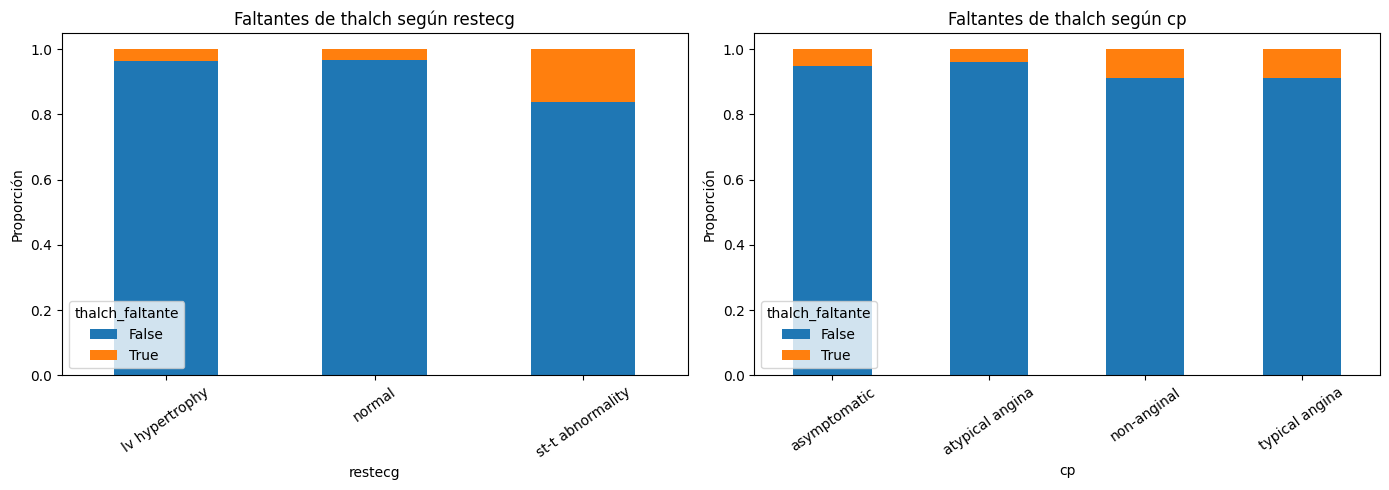

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, variable in enumerate(['restecg', 'cp']):

    tabla = pd.crosstab(
        cardio_df[variable],
        cardio_df['thalch_faltante'],
        normalize='index'
    )

    tabla.plot(
        kind='bar',
        stacked=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Faltantes de thalch según {variable}')
    axes[i].set_ylabel('Proporción')
    axes[i].tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.show()

In [55]:
# Prueba de chi-cuadrada de independencia para investigar si dos variables categoricas estan asociadas.

for variable in ['restecg', 'cp']:

    tabla = pd.crosstab(
        cardio_df[variable],
        cardio_df['thalch_faltante']
    )

    chi2, p_valor, grados_libertad, esperados = (
        stats.chi2_contingency(tabla)
    )

    print(f"\nVariable: {variable}")
    print(f"Valor p: {p_valor:.8f}")

    if p_valor < 0.05:
        print("Existe una asociación significativa")
    else:
        print("No se encontró asociación significativa")


Variable: restecg
Valor p: 0.00000000
Existe una asociación significativa

Variable: cp
Valor p: 0.15420097
No se encontró asociación significativa


Significado de las variables:

* restecg -
* cp -

Considerando los resultados de asociación, podemos inferir que los pacientes con anomalías ST-T en el electrocardiograma presentan una mayor proporción de valores faltantes en la frecuencia máxima cardiaca registrada.

Determinar si el mecanismo de faltantes es MCAR o MAR

* MCAR - Los valores faltan completamente al azar, sin relación con variables observadas ni con el valor ausente.
* MAR - La probabilidad de que falte un valor puede explicarse mediante variables observadas.

De acuerdo con estas definiciones y los resultados que muestran asociaciones estadísticamente significativas entre la ausencia de thalch (frecuencia cardiaca máxima registrada) y las variables age () y restecg (); MAR es una hipótesis razonable, porque la ausencia parece depender de caracteristicas observadas de los pacientes.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [56]:
cardio_df.drop(
    columns='thalch_faltante',
    inplace=True
)

In [57]:
numericas_grupo = ['thalch', 'trestbps', 'oldpeak']

for variable in numericas_grupo:

    cardio_df[variable] = (
        cardio_df.groupby(
            'restecg',
            observed=True
        )[variable]
        .transform(
            lambda x: x.fillna(x.median())
        )
    )


In [60]:
cardio_df.groupby('restecg')[variable].transform(lambda x: x.fillna(x.median()))

/tmp/ipykernel_1937/3633613099.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cardio_df.groupby('restecg')[variable].transform(lambda x: x.fillna(x.median()))


,oldpeak
id,
1,2.3
2,1.5
3,2.6
4,3.5
5,1.4
...,...
916,0.0
917,0.9
918,0.0


In [61]:
cardio_df['exang'] = (
    cardio_df.groupby(
        'restecg',
        observed=True
    )['exang']
    .transform(
        lambda x: x.fillna(x.mode().iloc[0])
    )
)

In [62]:
print(
    cardio_df[
        ['thalch', 'trestbps', 'oldpeak', 'exang']
    ].isna().sum()
)

thalch      0
trestbps    0
oldpeak     0
exang       0
dtype: int64


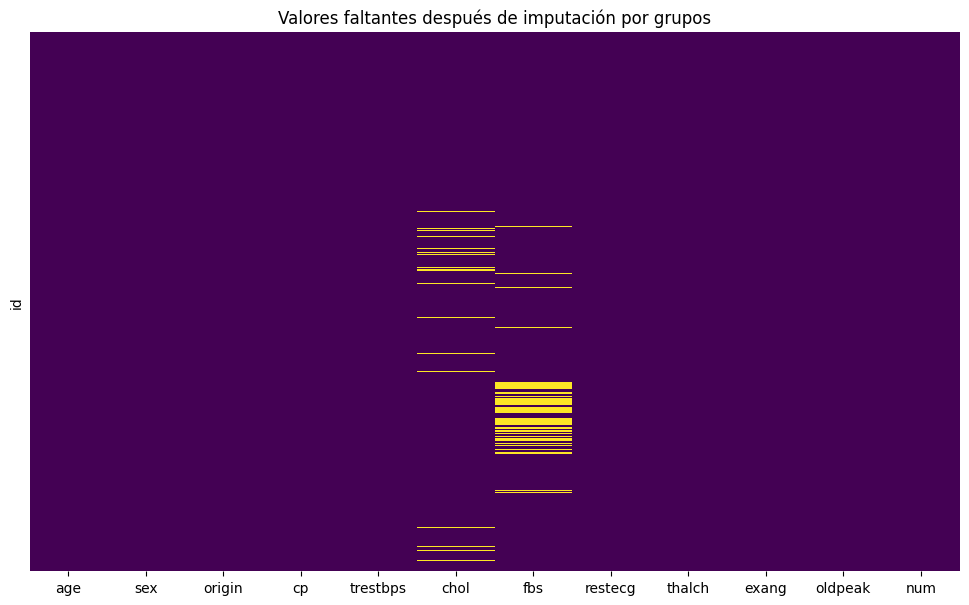

In [63]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    cardio_df.isna(),
    cmap='viridis',
    cbar=False,
    yticklabels=False
)

plt.title('Valores faltantes después de imputación por grupos')
plt.show()

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [64]:
cardio_df.isna().sum()

,0
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,30
fbs,89
restecg,0
thalch,0
exang,0


* chol (colesterol). Faltantes originales 30.  Usaremos la estrategia median ya que el colesterol es una variable numérica y puede presentar valores extremos.  La mediana es menos sensible a esos valores que la media.

* fbs (variable categórica que representa si la glucosa en ayunas supera los 120mg/dl.  Usaremos la estrategia de la moda ya que no tendría sentido sustituir sus faltantes por un promedio numérico.

In [66]:
# Imputar colesterol con la mediana

imputador_mediana = SimpleImputer(
    strategy='median'
)

cardio_df[['chol']] = imputador_mediana.fit_transform(
    cardio_df[['chol']]
)


In [67]:
# Imputar glucosa en ayunas con la moda

imputador_moda = SimpleImputer(
    strategy='most_frequent'
)

cardio_df[['fbs']] = imputador_moda.fit_transform(
    cardio_df[['fbs']]
)

cardio_df['fbs'] = cardio_df['fbs'].astype('category')

In [68]:
# comprobar que no quedaron faltantes

print("Valores faltantes restantes:")
print(cardio_df.isna().sum())

print("\nTotal de valores faltantes:")
print(cardio_df.isna().sum().sum())

Valores faltantes restantes:
age         0
sex         0
origin      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
dtype: int64

Total de valores faltantes:
0


8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

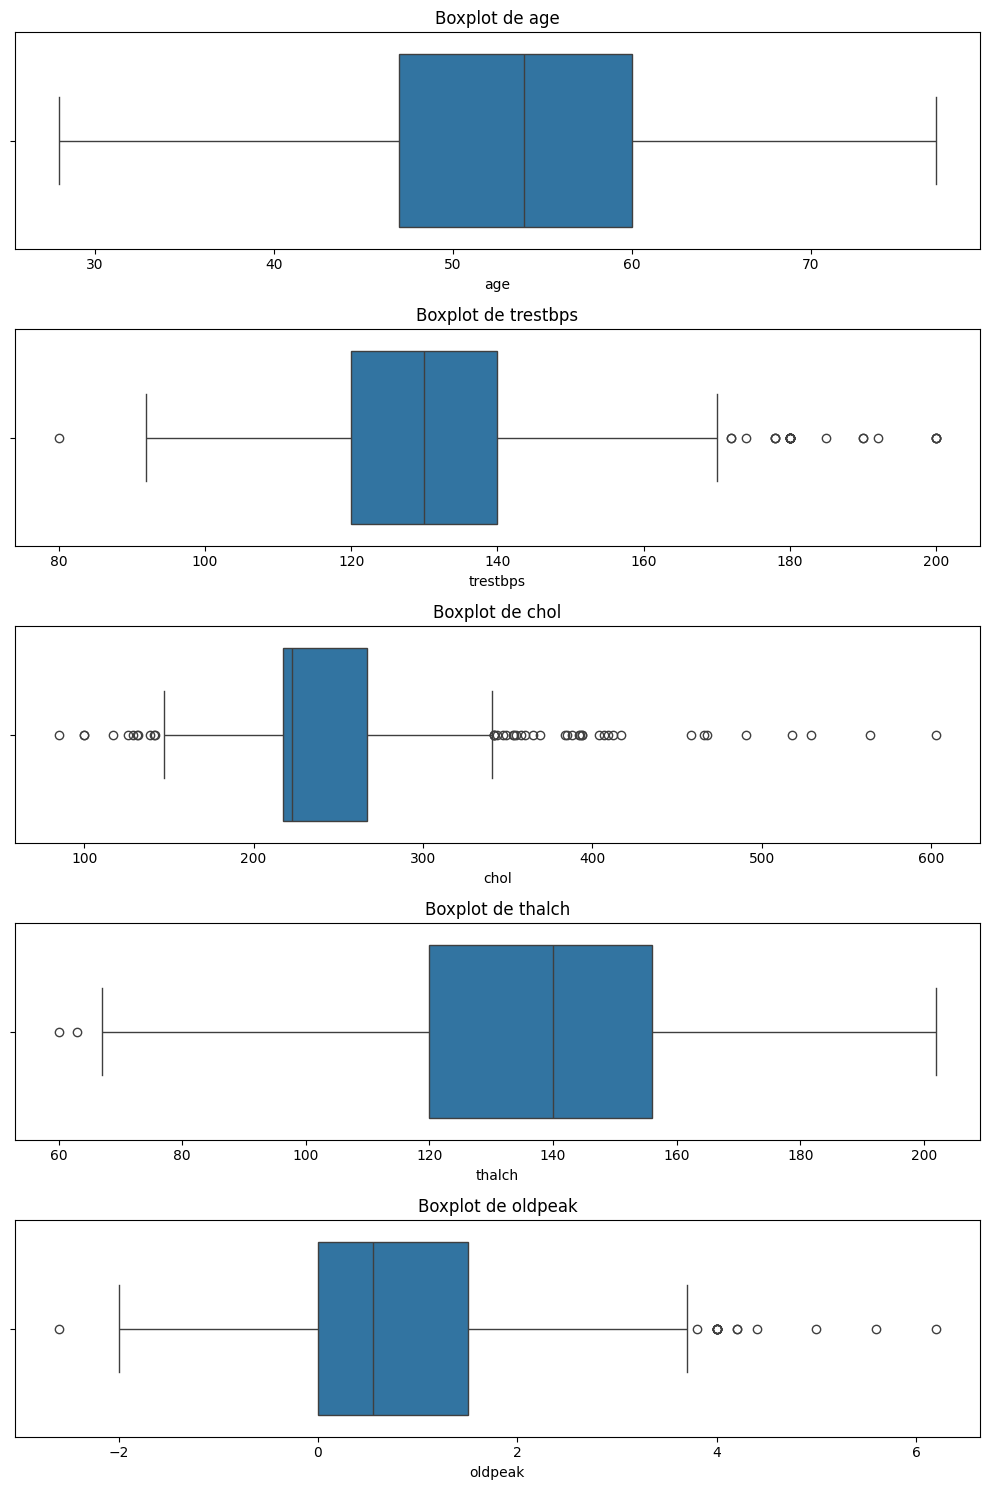

In [69]:
columnas_numericas = cardio_df.select_dtypes(
    include='number'
).columns

fig, axes = plt.subplots(
    len(columnas_numericas),
    1,
    figsize=(10, 3 * len(columnas_numericas))
)

for i, variable in enumerate(columnas_numericas):
    sns.boxplot(
        x=cardio_df[variable],
        ax=axes[i]
    )

    axes[i].set_title(f'Boxplot de {variable}')

plt.tight_layout()
plt.show()


Variable: age
Cantidad de atípicos: 0
Valores: []


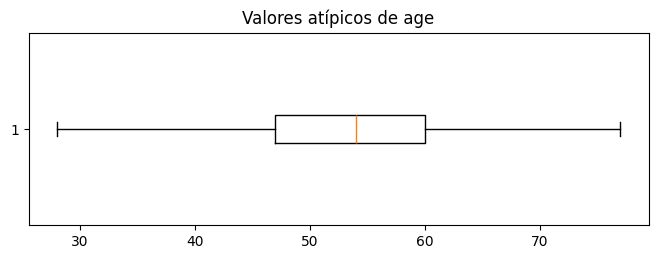


Variable: trestbps
Cantidad de atípicos: 27
Valores: [ 80. 172. 180. 200. 174. 178. 192. 180. 178. 180. 190. 180. 180. 180.
 180. 200. 180. 180. 180. 200. 185. 200. 180. 178. 172. 180. 190.]


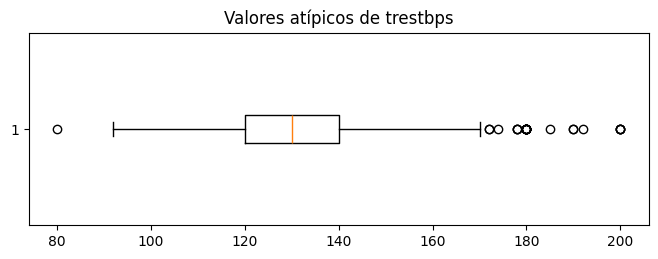


Variable: chol
Cantidad de atípicos: 44
Valores: [141. 126. 131. 132. 129. 100.  85. 117. 100. 142. 139. 354. 353. 417.
 360. 407. 564. 394. 409. 342. 358. 412. 468. 365. 344. 394. 347. 466.
 529. 392. 355. 603. 342. 404. 518. 388. 491. 342. 393. 458. 384. 349.
 369. 385.]


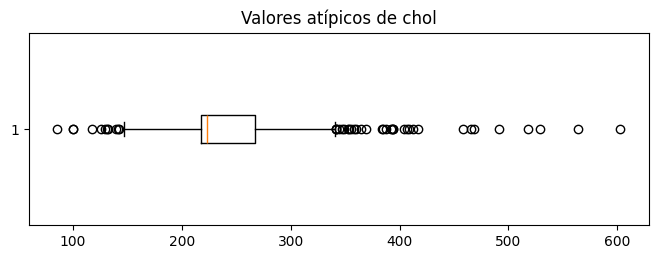


Variable: thalch
Cantidad de atípicos: 2
Valores: [60. 63.]


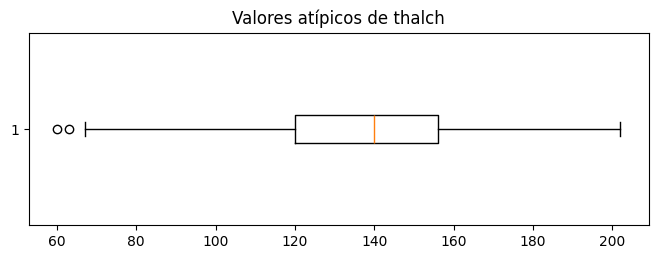


Variable: oldpeak
Cantidad de atípicos: 16
Valores: [-2.6  6.2  4.   5.6  4.   4.2  4.2  3.8  4.4  4.   4.   5.   4.   4.
  4.   4. ]


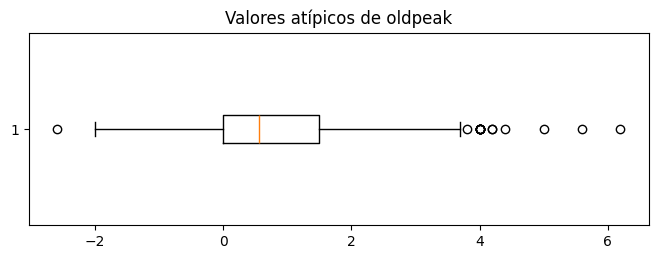

In [70]:
for variable in columnas_numericas:

    fig, ax = plt.subplots(figsize=(8, 2.5))

    resultado = ax.boxplot(
        cardio_df[variable].dropna(),
        vert=False
    )

    atipicos = resultado['fliers'][0].get_xdata()

    print(f"\nVariable: {variable}")
    print(f"Cantidad de atípicos: {len(atipicos)}")
    print(f"Valores: {atipicos}")

    ax.set_title(f'Valores atípicos de {variable}')

    plt.show()

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [71]:
# Calcular los cuartiles

Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)


Q1: 120.0
Q3: 140.0
IQR: 20.0
Límite inferior: 90.0
Límite superior: 170.0


In [72]:
atipicos_iqr = cardio_df[
    (cardio_df['trestbps'] < limite_inferior) |
    (cardio_df['trestbps'] > limite_superior)
]

print("Cantidad de valores atípicos:", len(atipicos_iqr))

display(atipicos_iqr[['trestbps']])

Cantidad de valores atípicos: 27


,trestbps
id,
15,172.0
84,180.0
127,200.0
173,174.0
184,178.0
189,192.0
202,180.0
214,178.0
232,180.0


Atípicos por boxplot: 27
Atípicos por IQR: 27
¿Coinciden los resultados? True


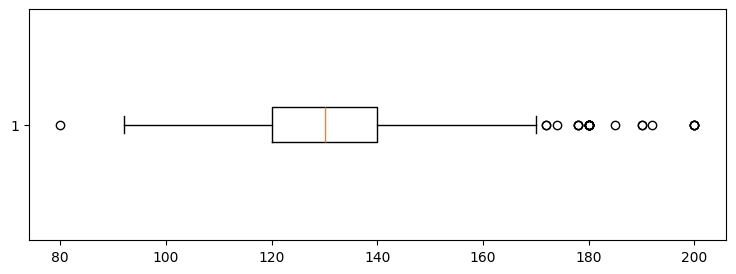

In [73]:
fig, ax = plt.subplots(figsize=(9, 3))

resultado = ax.boxplot(
    cardio_df['trestbps'],
    vert=False
)

atipicos_grafico = resultado['fliers'][0].get_xdata()

print("Atípicos por boxplot:", len(atipicos_grafico))
print("Atípicos por IQR:", len(atipicos_iqr))

coinciden = np.array_equal(
    np.sort(atipicos_grafico),
    np.sort(atipicos_iqr['trestbps'].to_numpy())
)

print("¿Coinciden los resultados?", coinciden)

plt.show()

Los valores atipicos encontrados a través del método gráfico y IQR coinciden.  Resultado de ambos 27

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [74]:
# Antes de eliminar los valores atípicos, conservar una copia de seguridad

cardio_df_original = cardio_df.copy()

In [75]:
cardio_df = cardio_df[
    (cardio_df['trestbps'] >= limite_inferior) &
    (cardio_df['trestbps'] <= limite_superior)
].copy()

print("Registros originales:", len(cardio_df_original))
print("Registros restantes:", len(cardio_df))
print(
    "Registros eliminados:",
    len(cardio_df_original) - len(cardio_df)
)

Registros originales: 918
Registros restantes: 891
Registros eliminados: 27


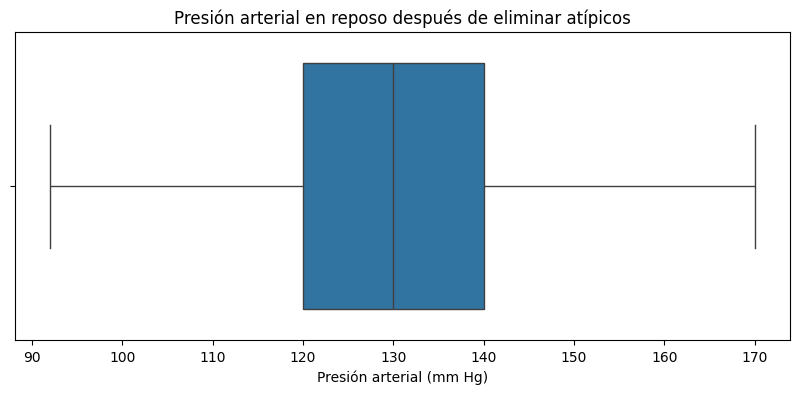

In [76]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=cardio_df['trestbps']
)

plt.title('Presión arterial en reposo después de eliminar atípicos')
plt.xlabel('Presión arterial (mm Hg)')

plt.show()


---

**Declaración de uso de IA**


*   OpenAI. (2026). *ChatGPT (basado en GPT-6)* [Modelo de lenguaje grande], utilizado para depuración de código y explicación de términos médicos del ejercicio. https://chat.openai.com/

* Gemini. (2026). Gemini 3.5 Flash [Modelo de lenguaje], usado para la revisión y corrección de errores de syntaxis en código. https://gemini.google.com/

---